# 06 残差与硬软约束

2exp(-t)的残差为零，但初值错误。新增硬/软约束对照需要至少三个随机种子。

默认仅运行 **smoke**；两轮训练只用于理解流程。把 `MODE` 改成 `reproduction` 才会按文档配置训练。

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image

# 同时支持从项目根目录或 notebooks 目录启动。
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "请从项目目录打开 Notebook"
sys.path.insert(0, str(ROOT / "src"))
from ndeq_examples.runner import run, environment
MODE = "smoke"
SEED = 42
environment()

<PROJECT_ROOT>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.6',
 'platform': 'Windows-11-10.0.26200-SP0',
 'packages': {'torch': '2.6.0+cpu',
  'neurodiffeq': '0.7.0',
  'numpy': '1.26.4',
  'scipy': '1.15.2',
  'matplotlib': '3.9.2',
  'pandas': '2.2.3',
  'pillow': '10.4.0'},
 'neurodiffeq_module_version': '0.6.3-dev'}

## residual_demo

先预测图像的大致形状，再运行下面的共享实现。

residual_demo: snippet_verified; numerical_pass=None; <PROJECT_ROOT>\results\notebook_runs\20261012T072020_residual_demo_smoke_s42_default_2d9843


{'checks_passed': True,
 'candidates': {'exp(-t)': {'residual_rmse': 0.0, 'initial_error': 0.0},
  '2 exp(-t)': {'residual_rmse': 0.0, 'initial_error': 1.0},
  '1-t': {'residual_rmse': 1.1575836902790224, 'initial_error': 0.0}}}

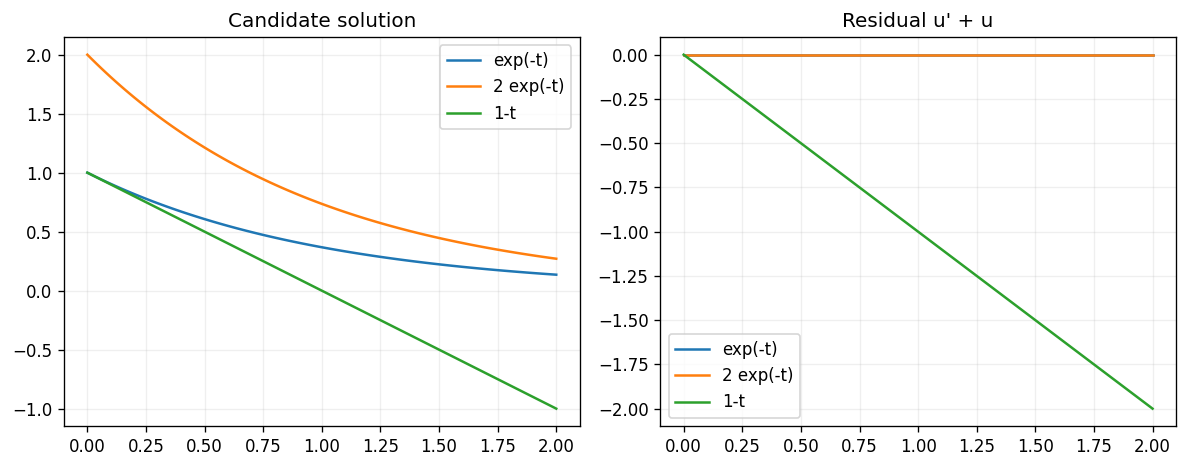

In [2]:
out = run("residual_demo", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## hard_constraint

先预测图像的大致形状，再运行下面的共享实现。

In [3]:
out = run("hard_constraint", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

hard_constraint: snippet_verified; numerical_pass=None; <PROJECT_ROOT>\results\notebook_runs\20261012T072021_hard_constraint_smoke_s42_default_543adc


{'checks_passed': True,
 'initial_error': 0.0,
 'initial_derivative_error': 0.0,
 'formula': '1 + (1-exp(-t))*N(t)'}

## 新增实验：硬约束和惩罚项

以下命令在终端运行，默认三个种子、两种约束。不要将单个种子的好结果推广为普遍结论。

```powershell
python -m ndeq_examples run --example hard_soft --mode benchmark --variants default soft
```

完成后运行 `python tools/build_report.py`，读取统计和对照图。

## 自查

- 这里的未知函数和自变量分别是什么？
- 初始/边界条件如何施加？
- metrics里哪一项是方程残差，哪一项是解误差？
- 当前是流程验证，还是完整训练？

详细说明见 `docs/learning_guide_zh.md` 和 `docs/validation_protocol.md`。